# Setup
If you have not run the below code in a separate Julia session, this notebook will not work.
```
using Pkg
Pkg.add("DrWatson")          
Pkg.activate("path/to/temp-tune")
Pkg.instantiate()

cd("path/to/temp-tune")
include(scriptsdir("setup_python.jl"))
```

## activate project

In [1]:
using Pkg
using DrWatson
@quickactivate "temp-tune"
println("current active project = ",Base.active_project())

current active project = /Users/pfields/Git/temp-tune/Project.toml


## setup plotting

In [2]:
include(srcdir("matplotlib_helpers.jl"))
setup_notebook_for_paper()
using_Py(true)

setup_rc_reset()
set_plot_style_for_paper(; venue="revtex")

Plot style set → venue=revtex, font='Arial'
Sizes (pt): label=10.0  tick=8.0  legend=8.0  mathtext.fontset=cm
Python     : /Users/pfields/Git/temp-tune/.conda/bin/python
Matplotlib : 3.10.8 | backend=Agg
 set plot style finished. exiting...



## other packages

In [3]:
using StatsBase, Statistics, LinearAlgebra, Printf, Random
using SpecialFunctions
using Parameters, Flux
using Optim, BenchmarkTools, JLD2, DataFrames, Graphs
using OptimizationOptimJL, Optimization
using Roots, Expectations
using Distributions
using Conda
using Dierckx
using CUDA
using SpinModels

In [4]:
include(srcdir("sweep_nn_ising.jl"))
include(srcdir("nearest_neighbor_ising.jl"))
include(srcdir("samplers.jl"))
include(srcdir("plot_ising_funcs.jl"))

tau_prime_plot (generic function with 1 method)

# import sims from paper
see instructions in README.md for downloading data

may take 2-3 minutes to import and process data

In [5]:
nreps = 10



nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), 
                stop=log10(1500), length=50))))[2:4:end]
true_temps_to_sweep=[ collect(2.00:0.05:3) ; collect(3.2:0.2:5) ]
mu_vals_to_sweep = []
tau_sweep_opts_4by4 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );



nsamples_to_sweep = Int.(round.( collect( range(; start=2000, stop=10_000, length=4))))
true_temps_to_sweep=[ collect(2.00:0.05:3) ; collect(3.2:0.2:5) ]
tau_sweep_opts_4by4_2 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );



true_temps_to_sweep_3 = collect(3.05:0.05:3.15)
nsamples_to_sweep = Int.(round.(10 .^collect(range(;start=log10(50), 
                stop=log10(1500), length=50))))[2:4:end]
append!( nsamples_to_sweep,
    Int.(round.( collect( range(; start=2000, stop=10_000, length=4)))))
tau_sweep_opts_4by4_3 = TauSweepOptions(nreps, mu_vals_to_sweep, 
    true_temps_to_sweep_3, "constant M", m_by_n=(4,4), 
    nsamples_to_sweep = nsamples_to_sweep );



savedir  =datadir("ising_sweeps", "constant_M_4by4")
savedir_2=datadir("ising_sweeps", "constant_M_4by4_2")
savedir_3=datadir("ising_sweeps", "constant_M_4by4_3")

"/Users/pfields/Git/temp-tune/data/ising_sweeps/constant_M_4by4_3"

In [6]:
df_raw_all_reps = DataFrame() 

append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_4by4, savedir ) )
append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_4by4_2, savedir_2 ) )
append!( df_raw_all_reps, load_from_sweeps( tau_sweep_opts_4by4_3, savedir_3 ) )


df_raw_all_reps = unique( df_raw_all_reps );

size(df_raw_all_reps)

(578, 13)

In [7]:
df_means_and_splines = DataFrame()

append!( df_means_and_splines, get_means_and_splines_df( tau_sweep_opts_4by4, df_raw_all_reps ) )
append!( df_means_and_splines, get_means_and_splines_df( tau_sweep_opts_4by4_2, df_raw_all_reps ) )
append!( df_means_and_splines, get_means_and_splines_df( tau_sweep_opts_4by4_3, df_raw_all_reps ) )


df_means_and_splines = unique(df_means_and_splines)

size(df_means_and_splines)

(578, 29)

In [8]:
df_tau_opt_DeltaDkl = DataFrame()

append!( df_tau_opt_DeltaDkl , get_tau_opt_df( tau_sweep_opts_4by4, df_means_and_splines ) )
append!( df_tau_opt_DeltaDkl , get_tau_opt_df( tau_sweep_opts_4by4_2, df_means_and_splines ) )
append!( df_tau_opt_DeltaDkl , get_tau_opt_df( tau_sweep_opts_4by4_3, df_means_and_splines ) )


df_tau_opt_DeltaDkl = unique(df_tau_opt_DeltaDkl)

size(df_tau_opt_DeltaDkl)

(578, 25)

# Heat Capacity Analysis

In [9]:
function heat_capacities_exact_mod( Jij, temp, ml_exact_buffer_for_C )
    (; all_states, all_states_energy, Z, exp_neg_energies ) = ml_exact_buffer_for_C
    all_states_energy .= energy2spin(all_states, Jij )
    exp_neg_energies .= exp.(-all_states_energy./temp)
    sum!(Z, exp_neg_energies)
    p = exp_neg_energies ./ Z
    E_mean = sum(p.*all_states_energy)
    ΔE² = (all_states_energy .- E_mean) .^2
    ΔE³ = (all_states_energy .- E_mean) .^3
    C = sum(p .* ΔE²) / (temp^2)
    dCdtau = (sum(p .* ΔE³) / (temp^4)) - (2*sum(p .* ΔE²) / (temp^3))
    return C, dCdtau
end

heat_capacities_exact_mod (generic function with 1 method)

## Compute C_1, dC/dtau|_{tau=1}, C* for all (T, M, rep)

In [10]:
_, Jij_true = init_2dNN(4, 4)
hc_buffer = ExactMLBuffer(Jij_true)

df_hc = DataFrame(T=Float64[], M=Int[], rep=Int[],
    C_1=Float64[], dCdtau_at1=Float64[],
    C_star=Float64[], tau_star=Float64[],
    delta_C_over_delta_tau=Float64[])

for row in eachrow(df_raw_all_reps)
    T, M = row.T, row.M
    df_opt_row = filter(r -> r.T == T && r.M == M, df_tau_opt_DeltaDkl)
    isempty(df_opt_row) && continue
    tau_stars = df_opt_row[1, :dkl_blue_tau_opts]

    n = size(row.J_fit, 1)
    for rep in 1:n
        J = row.J_fit[rep, :, :]
        tau_star = tau_stars[rep]

        C_1, dCdtau_at1 = heat_capacities_exact_mod(J, 1.0, hc_buffer)
        C_star, _        = heat_capacities_exact_mod(J, tau_star, hc_buffer)

        delta_C_over_delta_tau = tau_star ≈ 1.0 ? NaN : (C_star - C_1) / (tau_star - 1.0)

        push!(df_hc, (T, M, rep, C_1, dCdtau_at1, C_star, tau_star, delta_C_over_delta_tau))
    end
end

size(df_hc)

(5780, 8)

## Plot 1: dC/dtau|_{tau=1} vs T for different M

In [11]:
# ?groupindices

In [12]:
# all_Ms

In [13]:
# all_Ts

In [16]:
T_low, T_high, Mplot = (2., 4., 54)
rep_low = 4
rep_high = 4



df_t_low = filter( r->r.T==T_low && r.M==Mplot, df_raw_all_reps)
J_fit_low= df_t_low.J_fit[][rep_low, :,:]
df_t_low_tau_opt = filter( r->r.T==T_low && r.M==Mplot, df_tau_opt_DeltaDkl )


df_t_high = filter( r->r.T==T_high && r.M==Mplot, df_raw_all_reps)
J_fit_high= df_t_high.J_fit[][rep_high, :,:]
df_t_high_tau_opt = filter( r->r.T==T_high && r.M==Mplot, df_tau_opt_DeltaDkl )

tau_opt_low = df_t_low_tau_opt.dkl_blue_tau_opts[][rep_low]

tau_opt_high = df_t_high_tau_opt.dkl_blue_tau_opts[][rep_high]

tss=df_t_low.tau_swept[]
tss=collect(tss[1]:0.01:tss[end])

C_lowT, C_highT = ntuple(i -> similar(tss), 2) 
for (i,tt) in enumerate(tss)
    C_lowT[i]  = heat_capacities_exact_mod(J_fit_low, tt, hc_buffer)[1]
    C_highT[i] = heat_capacities_exact_mod(J_fit_high, tt, hc_buffer)[1]
end

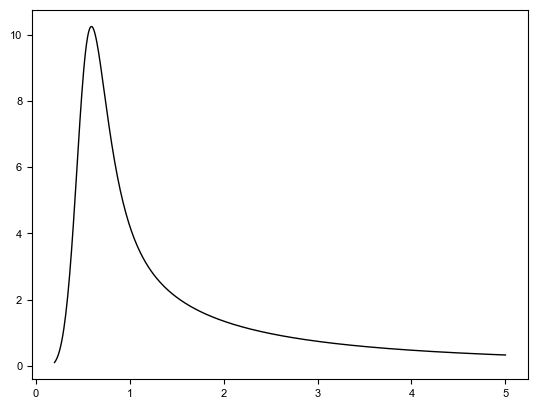

1-element Vector{PyObject}:
 PyObject <matplotlib.lines.Line2D object at 0x17b35c170>

In [17]:
plot(tss, C_highT, "k")

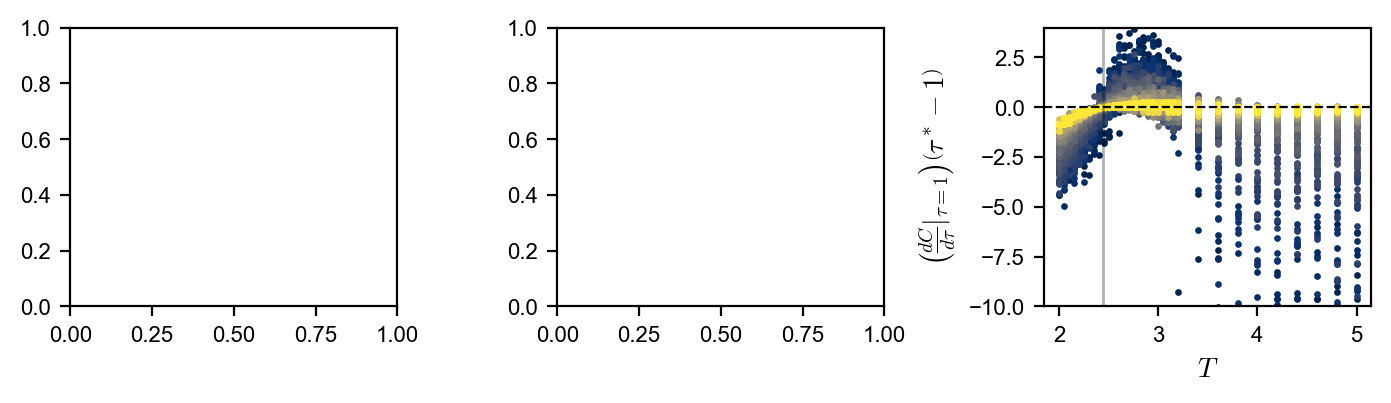

(-10.0, 4.0)

In [61]:
all_Ms = sort(unique(df_hc.M))
all_Ts = sort(unique(df_hc.T))

cc = get_cmap("cividis")
M_norm(m) = (log10(m) - log10(minimum(all_Ms))) / (log10(maximum(all_Ms)) - log10(minimum(all_Ms)))

fig, ax = subplots(1, 3, figsize=set_size_for_paper(2, 0.3), dpi=200)

heat_capacities_exact_mod( Jij, temp, ml_exact_buffer_for_C )



for M in all_Ms
    df_M = filter(r -> r.M == M, df_hc)
    # df_grouped = combine(groupby(df_M, :T),
    #     :dCdtau_at1 => mean => :dCdtau_mean,
    #     :dCdtau_at1 => std  => :dCdtau_std)
    # sort!(df_grouped, :T)

    cnow = cc(M_norm((M)))
    ts = df_M.tau_star 
    delta_tau=ts.-1
    ax[3].scatter(df_M.T, df_M.dCdtau_at1 .* delta_tau, color=cnow, s=2)
    
    # ax.plot(df_grouped.T, df_grouped.dCdtau_mean, color=cnow, label="M=$M")
    # ax.fill_between(df_grouped.T,
    #     df_grouped.dCdtau_mean .- df_grouped.dCdtau_std,
    #     df_grouped.dCdtau_mean .+ df_grouped.dCdtau_std,
    #     alpha=0.2, color=cnow)
end

ax[3].axhline(0, color="k", linewidth=0.8, linestyle="--")
ax[3].set_xlabel(L"T")
ax[3].set_ylabel(L"\left(\frac{dC}{d\tau}|_{\tau=1}\right)\left(\tau^* - 1\right)")
# ax[3].grid("on")
fig.tight_layout()
ax[3].vlines(2.439, -10,10, "k", alpha=0.3)
ax[3].set_ylim(-10,4)


In [52]:
cc

## Plot 2: (C* - C_1)/(tau* - 1) vs dC/dtau|_{tau=1}

Each point is one rep. Color = T. Different panels or marker sizes for M.

In [ ]:
df_hc.tau_star

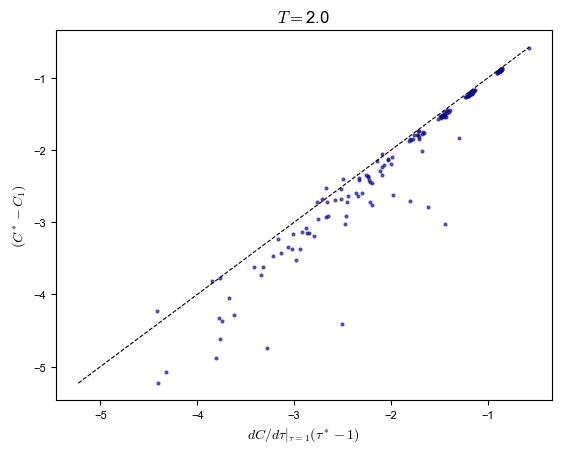

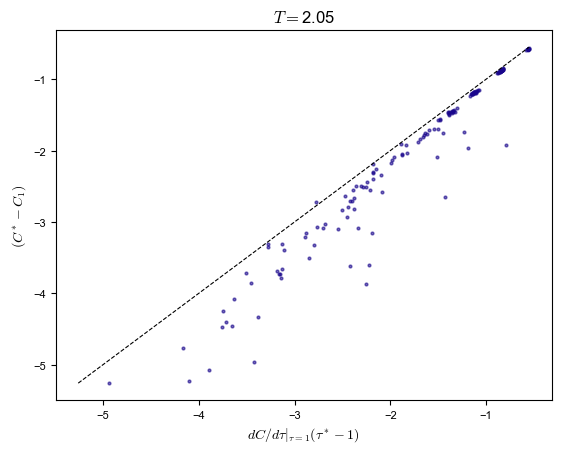

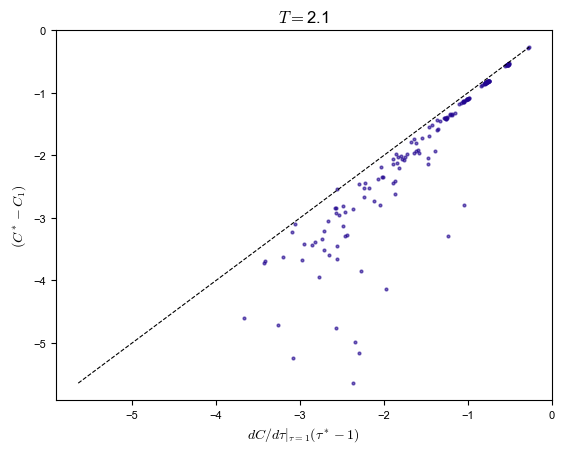

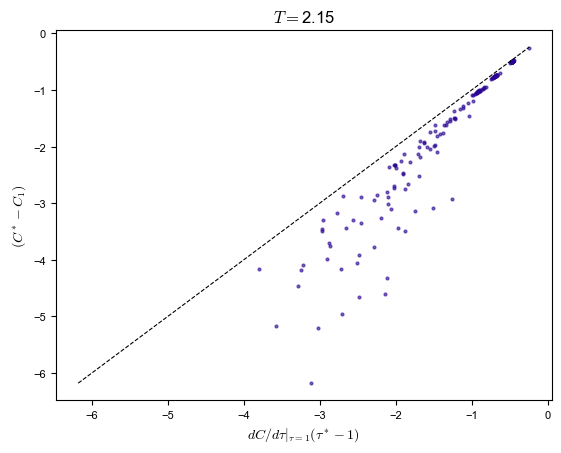

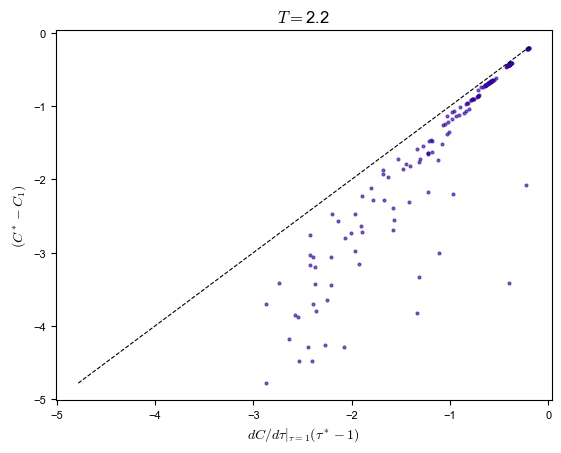

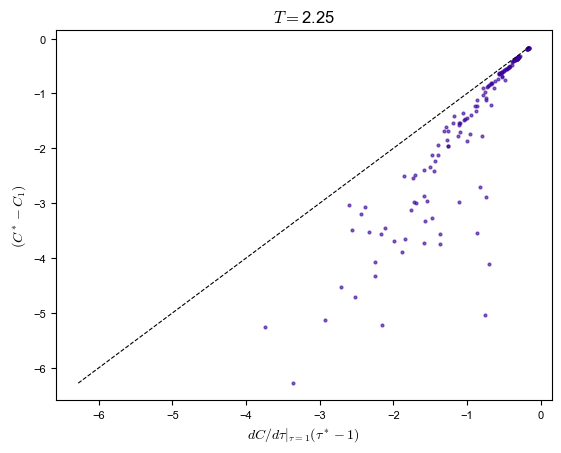

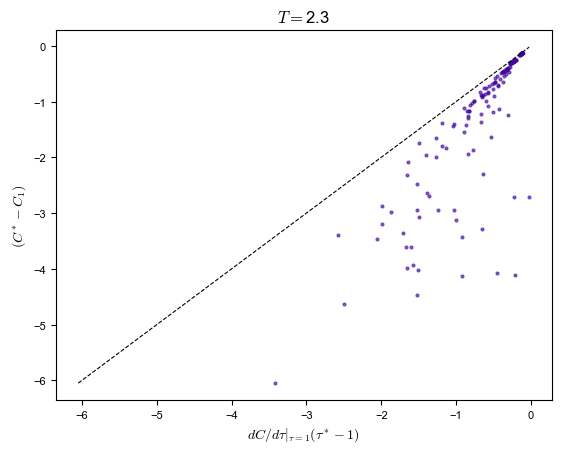

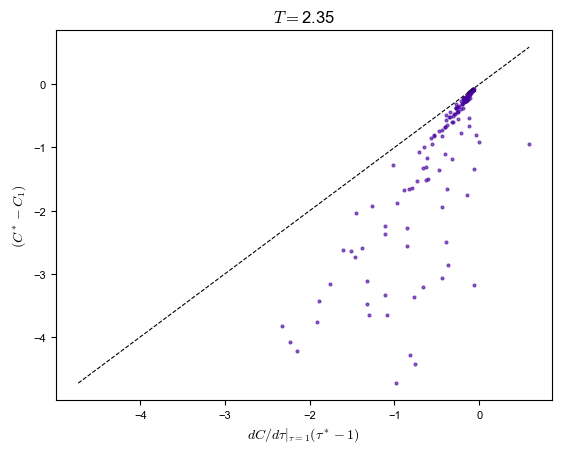

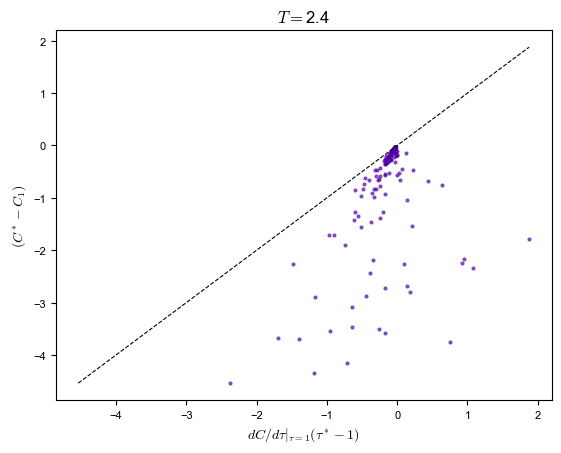

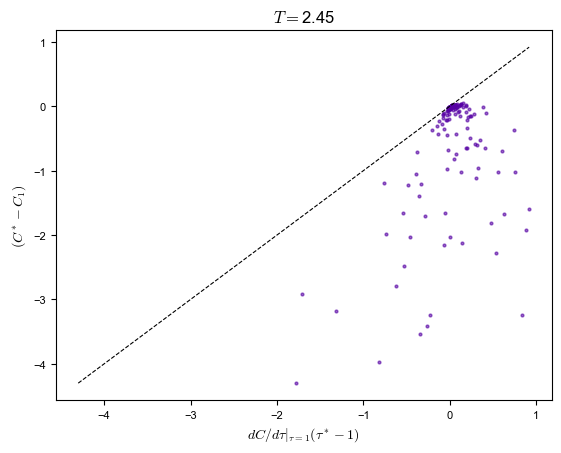

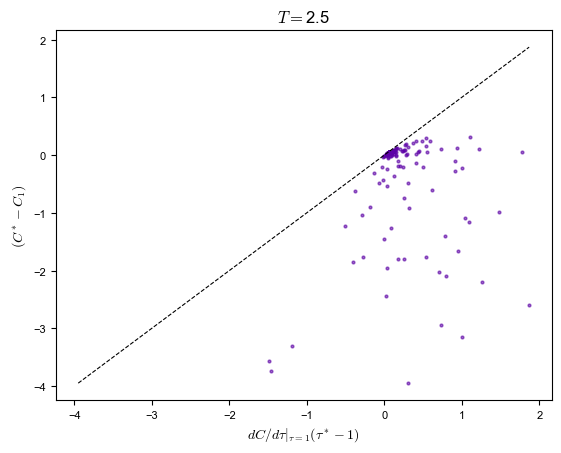

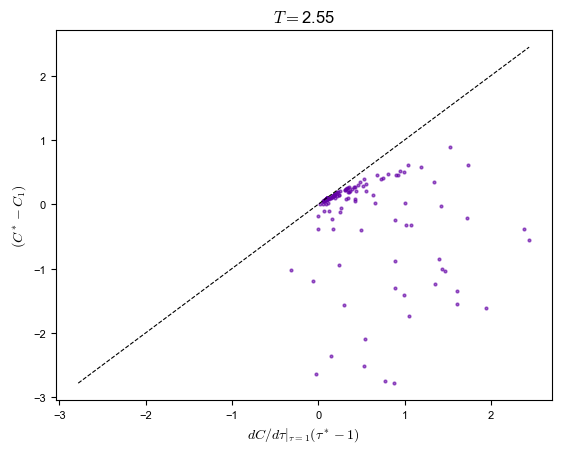

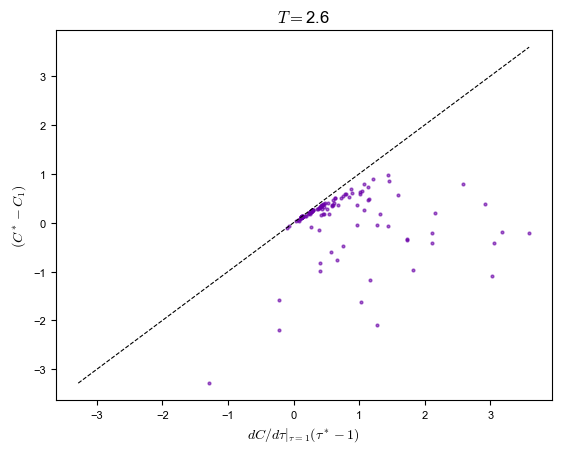

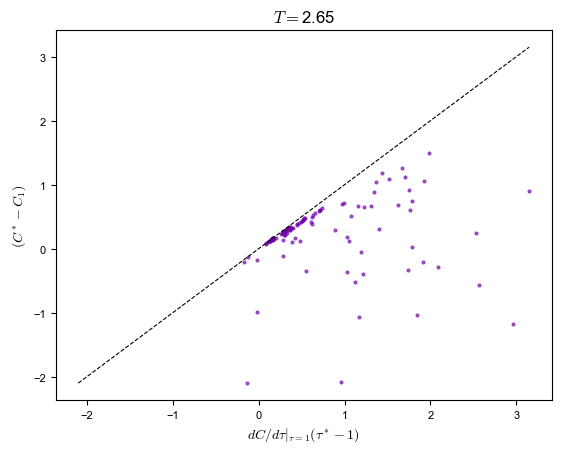

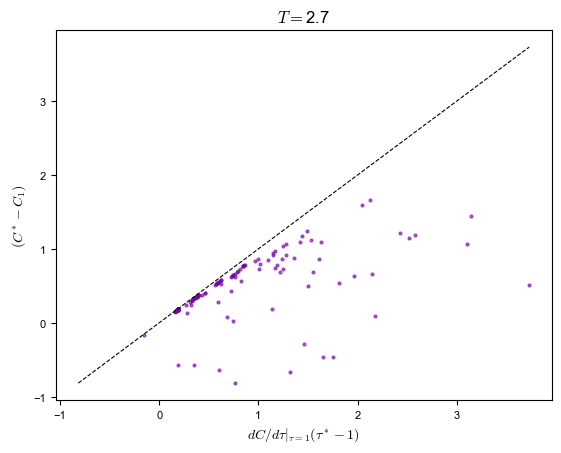

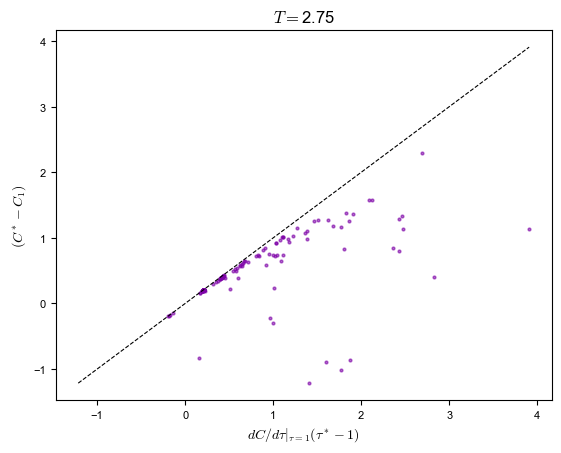

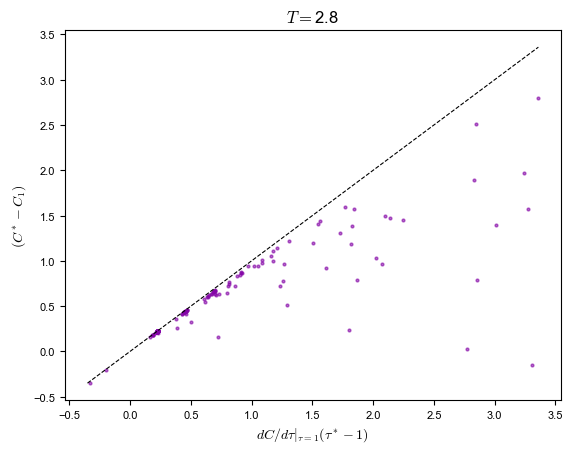

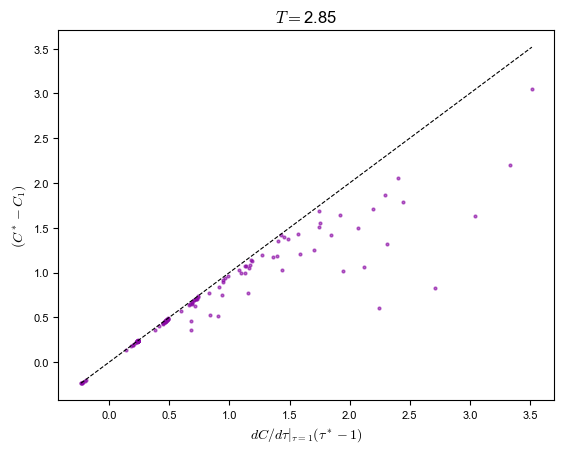

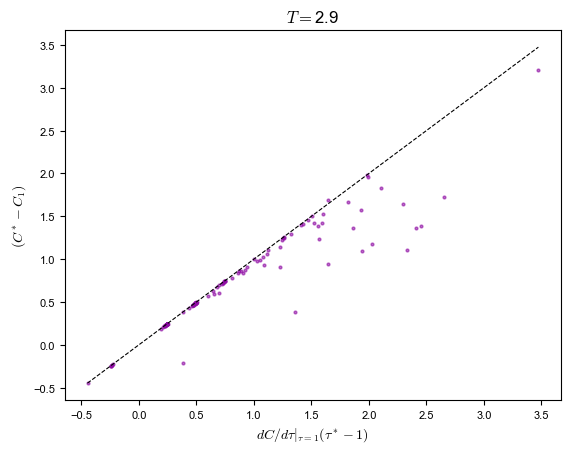

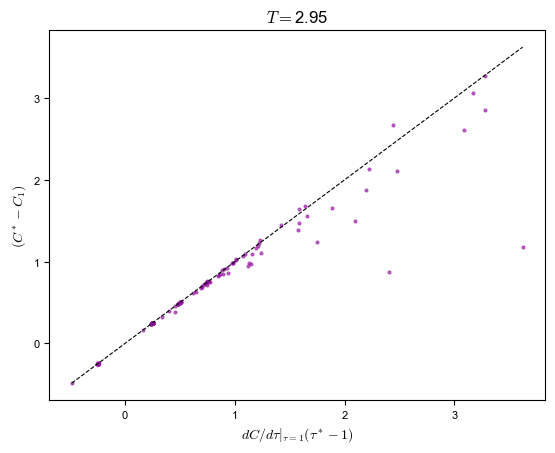

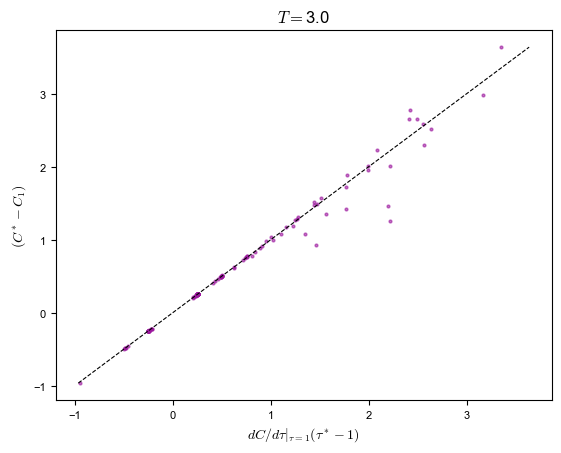

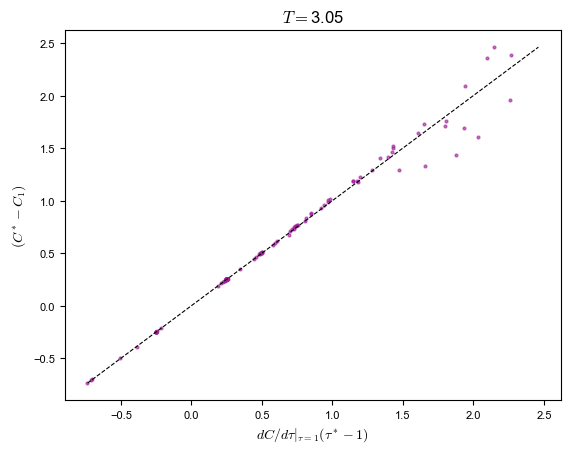

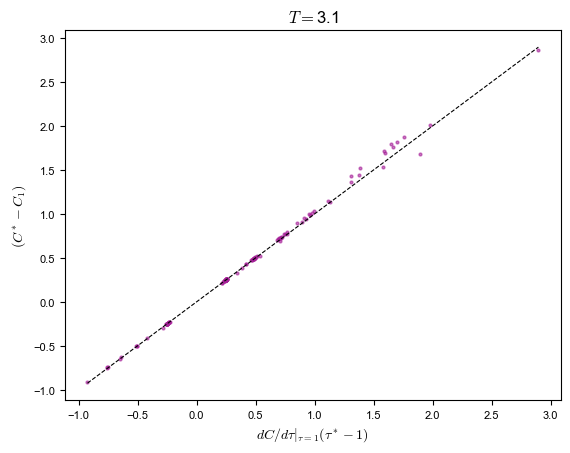

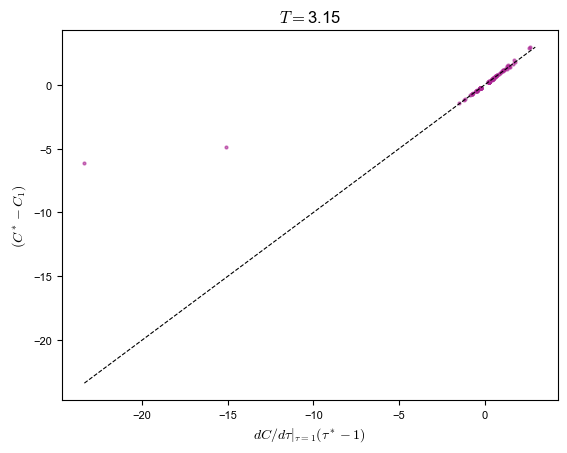

Figure(PyObject <Figure size 640x480 with 1 Axes>)

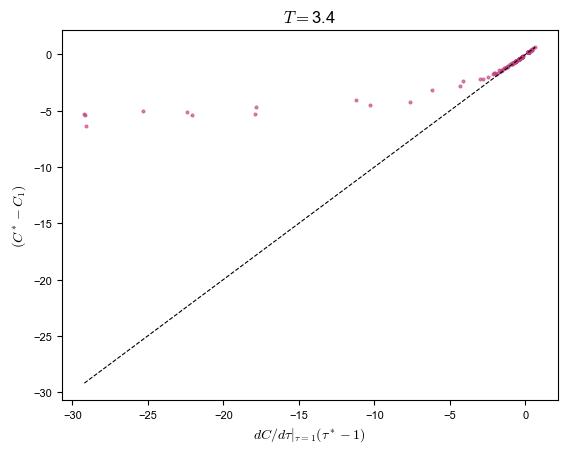

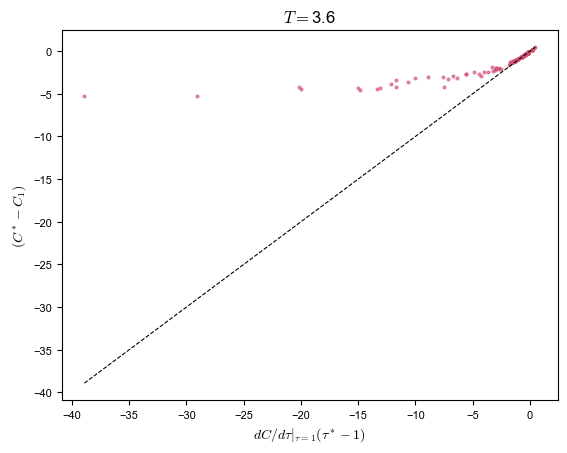

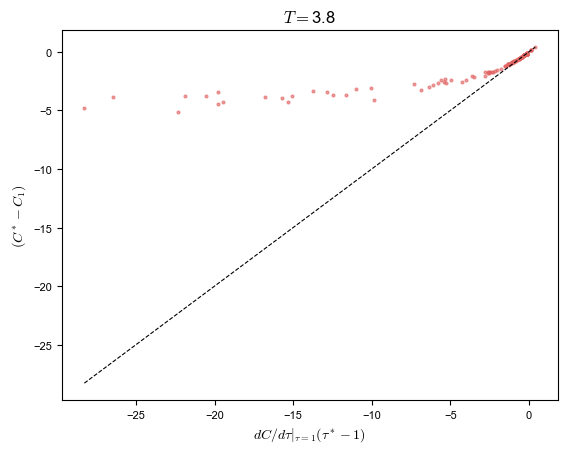

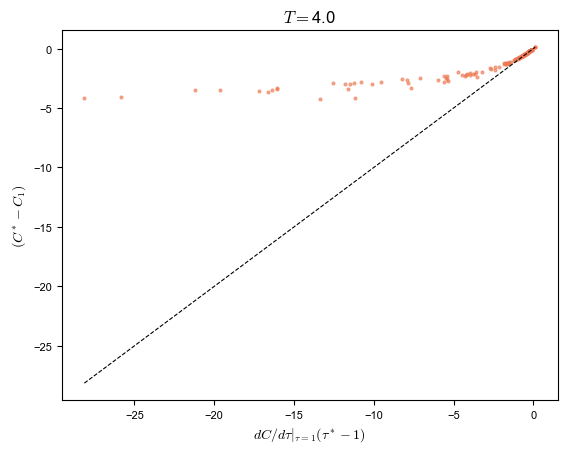

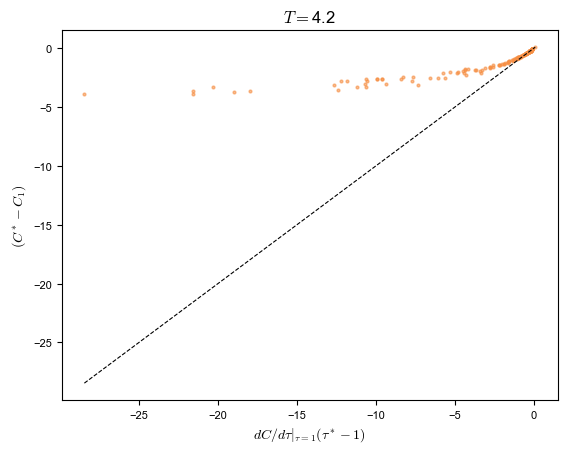

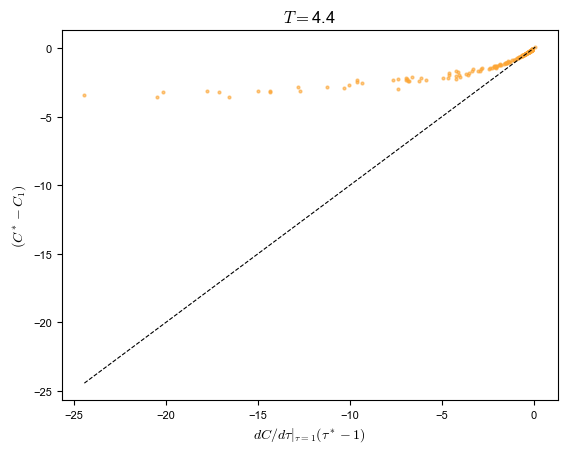

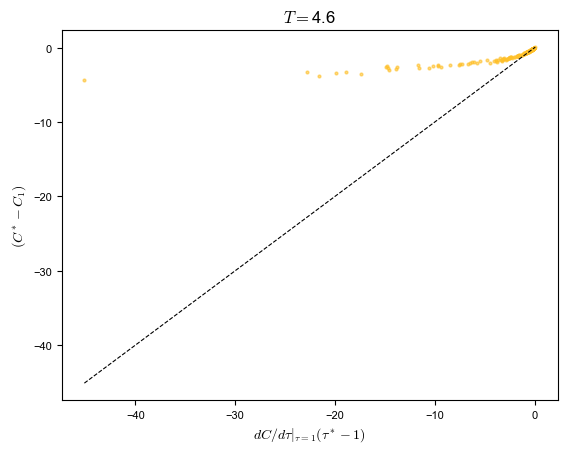

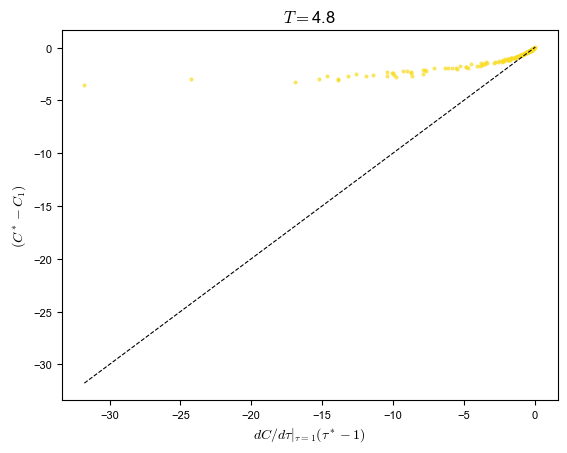

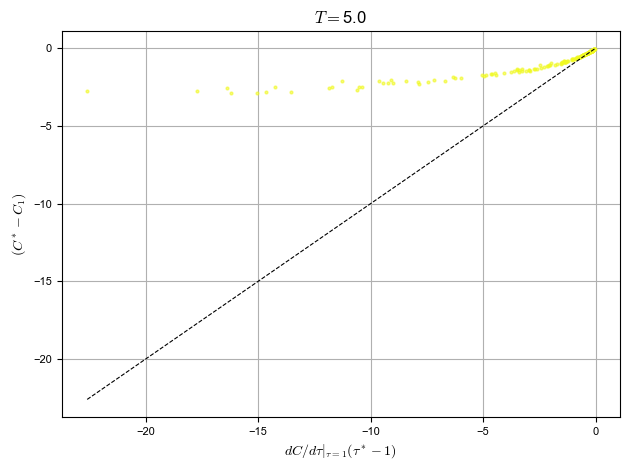

In [58]:
df_plot2 = filter(r -> !isnan(r.delta_C_over_delta_tau), df_hc)

T_norm(t) = (t - minimum(all_Ts)) / (maximum(all_Ts) - minimum(all_Ts))
cc_T = get_cmap("plasma")

# fig, ax = subplots(1, 1, figsize=set_size_for_paper(1, 0.9), dpi=200)

for T in all_Ts
    fig, ax = subplots()
    all_xy_curr = []
    for row in eachrow(filter( r -> r.T == T , df_plot2) )
        cnow = cc_T(T_norm(row.T))
        ts = row.tau_star 
        delta_tau=ts-1
        ax.scatter(row.dCdtau_at1 * delta_tau , row.delta_C_over_delta_tau *delta_tau,
            color=cnow, s=4, alpha=0.6, zorder=2)
        push!(all_xy_curr, row.dCdtau_at1 * delta_tau)
        push!(all_xy_curr, row.delta_C_over_delta_tau *delta_tau)
    end
    ax.set_title(L"T="*"$T")
    
    ax.set_xlabel(L"dC/d\tau|_{\tau=1} (\tau^* - 1)")
    ax.set_ylabel(L"(C^* - C_1)")
    xx = collect(range(minimum(all_xy_curr), maximum(all_xy_curr), length=100))
    ax.plot(xx, xx, "k--", linewidth=0.8 )
end

# identity line: if (C*-C1)/(tau*-1) = dC/dtau|1, first-order is exact
x_all = df_plot2.dCdtau_at1
xx = collect(range(minimum(x_all), maximum(x_all), length=100))
# ax.plot(xx, xx, "k--", linewidth=0.8, label="slope = 1 (1st order)")

# ax.legend(frameon=false)
ax.grid("on")
fig.tight_layout()